In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('dataset/india_electricity_load_dataset_FINAL.csv', parse_dates=['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

print(df.shape)
df.head()

(56808, 7)


,datetime,national_demand_mw,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,gdp_constant_crores
0,2019-01-01 00:00:00,118690.67,19.072472,26.414062,11.066474,0.0,13992914.0
1,2019-01-01 01:00:00,116029.23,19.072472,26.414062,11.066474,0.0,13992914.0
2,2019-01-01 02:00:00,114044.14,19.072472,26.414062,11.066474,0.0,13992914.0
3,2019-01-01 03:00:00,113648.97,19.072472,26.414062,11.066474,0.0,13992914.0
4,2019-01-01 04:00:00,116290.05,19.072472,26.414062,11.066474,0.0,13992914.0


In [3]:
df.isna().sum()

datetime               0
national_demand_mw     0
avg_temp_c             0
max_temp_c             0
min_temp_c             0
rainfall_mm            0
gdp_constant_crores    0
dtype: int64

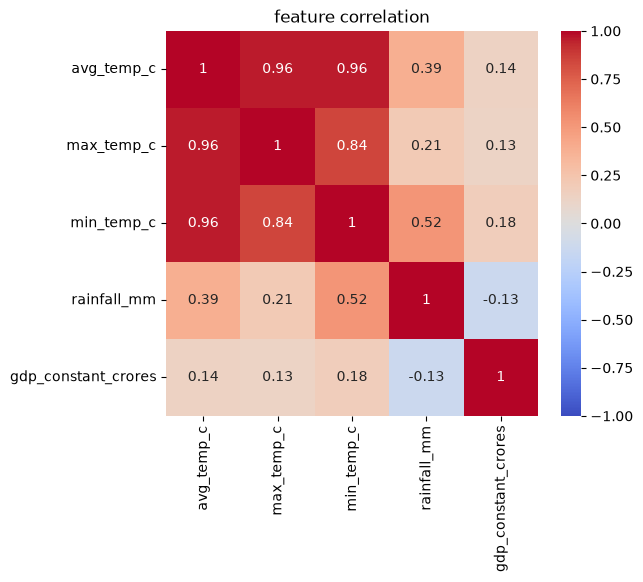

In [4]:
cols_to_check = ['avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'gdp_constant_crores']
corr = df[cols_to_check].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('feature correlation')
plt.show()

In [5]:
df = df.drop(columns=['max_temp_c', 'min_temp_c'])
df.head()

,datetime,national_demand_mw,avg_temp_c,rainfall_mm,gdp_constant_crores
0,2019-01-01 00:00:00,118690.67,19.072472,0.0,13992914.0
1,2019-01-01 01:00:00,116029.23,19.072472,0.0,13992914.0
2,2019-01-01 02:00:00,114044.14,19.072472,0.0,13992914.0
3,2019-01-01 03:00:00,113648.97,19.072472,0.0,13992914.0
4,2019-01-01 04:00:00,116290.05,19.072472,0.0,13992914.0


In [6]:
df['demand_lag1'] = df['national_demand_mw'].shift(1)
df['demand_lag24'] = df['national_demand_mw'].shift(24)
df['demand_lag168'] = df['national_demand_mw'].shift(168)

df.head(10)

,datetime,national_demand_mw,avg_temp_c,rainfall_mm,gdp_constant_crores,demand_lag1,demand_lag24,demand_lag168
0,2019-01-01 00:00:00,118690.67,19.072472,0.0,13992914.0,NaN,NaN,NaN
1,2019-01-01 01:00:00,116029.23,19.072472,0.0,13992914.0,118690.67,NaN,NaN
2,2019-01-01 02:00:00,114044.14,19.072472,0.0,13992914.0,116029.23,NaN,NaN
3,2019-01-01 03:00:00,113648.97,19.072472,0.0,13992914.0,114044.14,NaN,NaN
4,2019-01-01 04:00:00,116290.05,19.072472,0.0,13992914.0,113648.97,NaN,NaN
5,2019-01-01 05:00:00,124434.00,19.072472,0.0,13992914.0,116290.05,NaN,NaN
6,2019-01-01 06:00:00,136638.94,19.072472,0.0,13992914.0,124434.00,NaN,NaN
7,2019-01-01 07:00:00,147992.72,19.072472,0.0,13992914.0,136638.94,NaN,NaN
8,2019-01-01 08:00:00,153580.44,19.072472,0.0,13992914.0,147992.72,NaN,NaN
9,2019-01-01 09:00:00,156556.18,19.072472,0.0,13992914.0,153580.44,NaN,NaN


In [7]:
df['hour'] = df['datetime'].dt.hour
df['dayofweek'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month

df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['dow_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

df = df.drop(columns=['hour', 'dayofweek', 'month'])

In [8]:
df = df.dropna().reset_index(drop=True)
print(df.shape)

(56640, 14)


In [9]:
split_date = '2025-01-01'
train = df[df['datetime'] < split_date]
test = df[df['datetime'] >= split_date]

print(train.shape, test.shape)

(52440, 14) (4200, 14)


In [10]:
feature_cols = ['avg_temp_c', 'rainfall_mm', 'gdp_constant_crores',
                 'demand_lag1', 'demand_lag24', 'demand_lag168',
                 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']

X_train = train[feature_cols]
y_train = train['national_demand_mw']
X_test = test[feature_cols]
y_test = test['national_demand_mw']

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def get_metrics(y_true, y_pred, n_features):
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    adj_r2 = adjusted_r2(r2, len(y_true), n_features)
    return {'MAE': mae, 'MAPE': mape, 'RMSE': rmse, 'R2': r2, 'Adj_R2': adj_r2}

In [13]:
mlr = LinearRegression()
mlr.fit(X_train_scaled, y_train)
mlr_pred = mlr.predict(X_test_scaled)

mlr_metrics = get_metrics(y_test, mlr_pred, X_train.shape[1])
mlr_metrics

{'MAE': 3479.2522143782417,
 'MAPE': 1.7746476571318097,
 'RMSE': np.float64(5037.883640198502),
 'R2': 0.9336220554803285,
 'Adj_R2': 0.9334318153718413}

In [14]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_metrics = get_metrics(y_test, rf_pred, X_train.shape[1])
rf_metrics

{'MAE': 2728.6155629030563,
 'MAPE': 1.3806500136153468,
 'RMSE': np.float64(4158.288736400409),
 'R2': 0.9547772655755591,
 'Adj_R2': 0.9546476565922553}

In [15]:
from sklearn.svm import SVR

svr = SVR(kernel='rbf', C=100, gamma='scale')
svr.fit(X_train_scaled, y_train)
svr_pred = svr.predict(X_test_scaled)

svr_metrics = get_metrics(y_test, svr_pred, X_train.shape[1])
svr_metrics

{'MAE': 8038.878579081907,
 'MAPE': 3.878423271565299,
 'RMSE': np.float64(11261.44375898418),
 'R2': 0.6683227533977616,
 'Adj_R2': 0.6673721618144737}

In [16]:
results = pd.DataFrame({
    'MLR': mlr_metrics,
    'Random Forest': rf_metrics,
    'SVR': svr_metrics
}).T

results

,MAE,MAPE,RMSE,R2,Adj_R2
MLR,3479.252214,1.774648,5037.883640,0.933622,0.933432
Random Forest,2728.615563,1.380650,4158.288736,0.954777,0.954648
SVR,8038.878579,3.878423,11261.443759,0.668323,0.667372


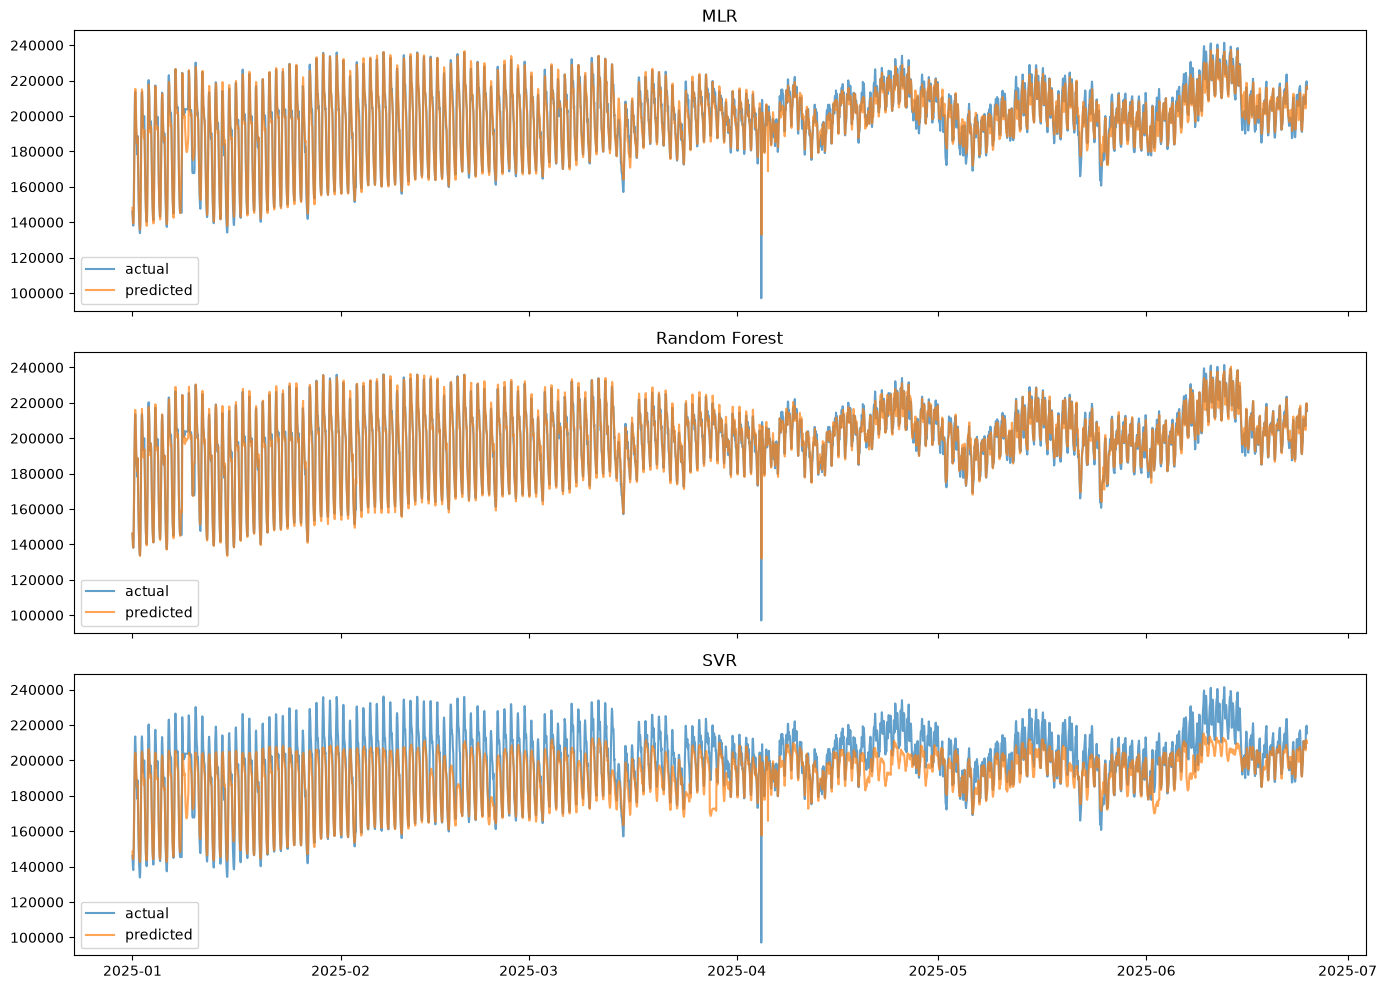

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(test['datetime'], y_test.values, label='actual', alpha=0.7)
axes[0].plot(test['datetime'], mlr_pred, label='predicted', alpha=0.7)
axes[0].set_title('MLR')
axes[0].legend()

axes[1].plot(test['datetime'], y_test.values, label='actual', alpha=0.7)
axes[1].plot(test['datetime'], rf_pred, label='predicted', alpha=0.7)
axes[1].set_title('Random Forest')
axes[1].legend()

axes[2].plot(test['datetime'], y_test.values, label='actual', alpha=0.7)
axes[2].plot(test['datetime'], svr_pred, label='predicted', alpha=0.7)
axes[2].set_title('SVR')
axes[2].legend()

plt.tight_layout()
plt.show()

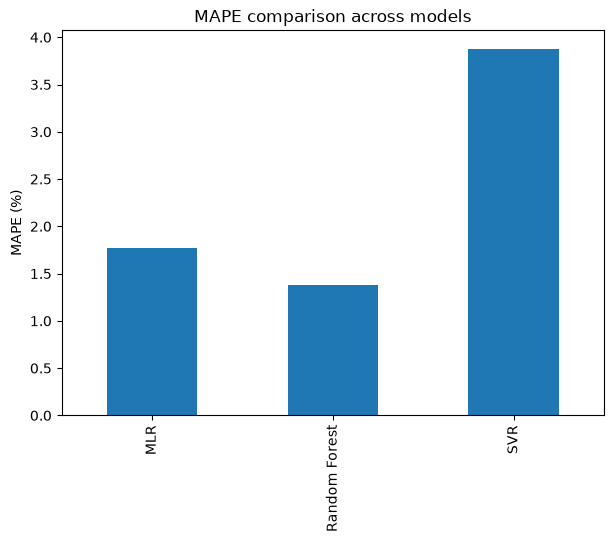

In [18]:
results[['MAPE']].plot(kind='bar', figsize=(7,5), legend=False)
plt.title('MAPE comparison across models')
plt.ylabel('MAPE (%)')
plt.show()

In [19]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVR

sample_idx = np.random.RandomState(42).choice(len(X_train_scaled), size=5000, replace=False)
X_sample = X_train_scaled[sample_idx]
y_sample = y_train.values[sample_idx]

param_dist = {
    'C': [10, 100, 1000, 5000],
    'gamma': ['scale', 0.01, 0.1],
    'epsilon': [0.01, 0.1, 1]
}

search = RandomizedSearchCV(SVR(kernel='rbf'), param_dist, n_iter=8, cv=3, scoring='neg_mean_absolute_percentage_error', random_state=42, n_jobs=-1)
search.fit(X_sample, y_sample)

print(search.best_params_)

{'gamma': 'scale', 'epsilon': 0.1, 'C': 5000}


In [20]:
svr_tuned = SVR(kernel='rbf', C=5000, gamma='scale', epsilon=0.1)
svr_tuned.fit(X_train_scaled, y_train)
svr_tuned_pred = svr_tuned.predict(X_test_scaled)

svr_tuned_metrics = get_metrics(y_test, svr_tuned_pred, X_train.shape[1])
svr_tuned_metrics

{'MAE': 4367.398264177943,
 'MAPE': 2.153331369625188,
 'RMSE': np.float64(6510.730670690595),
 'R2': 0.8891369058276788,
 'Adj_R2': 0.8888191706640609}

In [21]:
results = pd.DataFrame({
    'MLR': mlr_metrics,
    'Random Forest': rf_metrics,
    'SVR (untuned)': svr_metrics,
    'SVR (tuned)': svr_tuned_metrics
}).T

results

,MAE,MAPE,RMSE,R2,Adj_R2
MLR,3479.252214,1.774648,5037.883640,0.933622,0.933432
Random Forest,2728.615563,1.380650,4158.288736,0.954777,0.954648
SVR (untuned),8038.878579,3.878423,11261.443759,0.668323,0.667372
SVR (tuned),4367.398264,2.153331,6510.730671,0.889137,0.888819


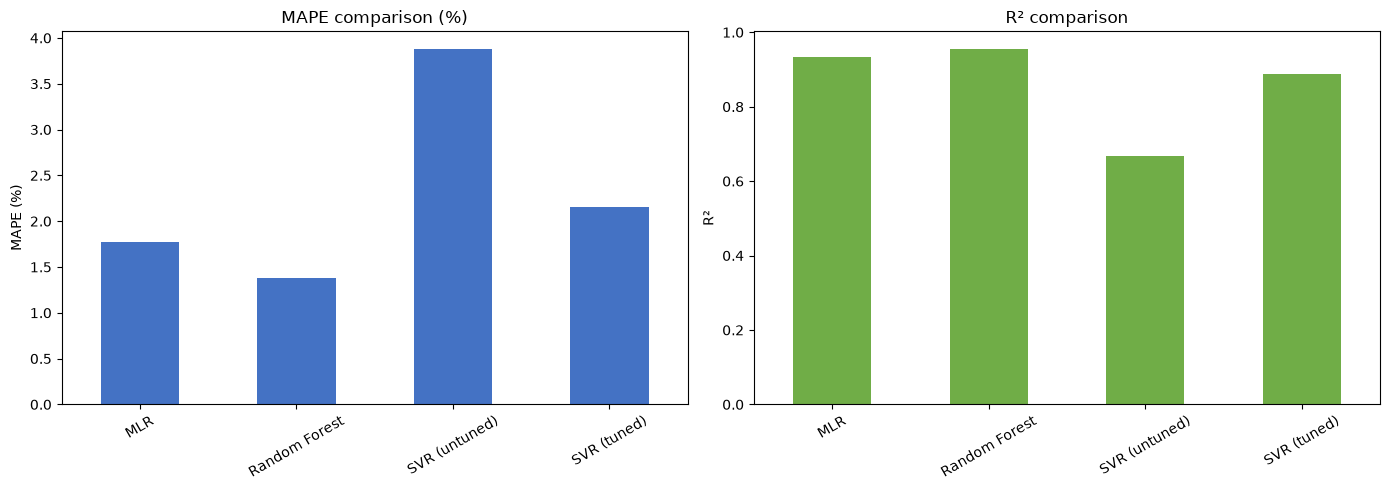

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results[['MAPE']].plot(kind='bar', ax=axes[0], legend=False, color='#4472C4')
axes[0].set_title('MAPE comparison (%)')
axes[0].set_ylabel('MAPE (%)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=30)

results[['R2']].plot(kind='bar', ax=axes[1], legend=False, color='#70AD47')
axes[1].set_title('R² comparison')
axes[1].set_ylabel('R²')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

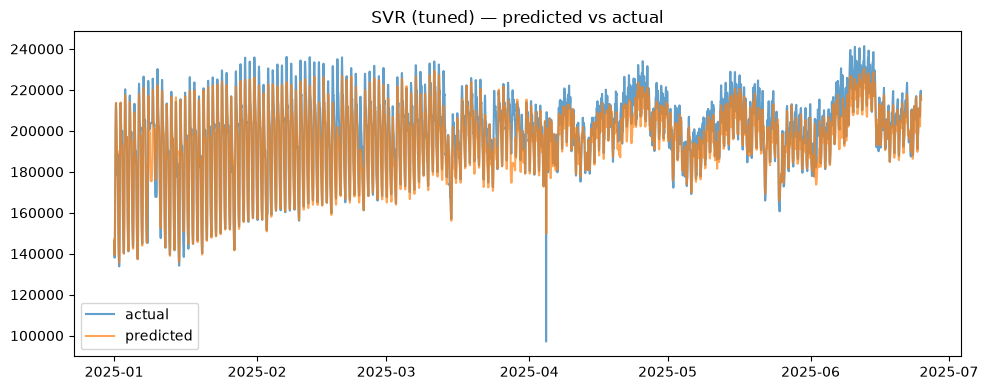

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(test['datetime'], y_test.values, label='actual', alpha=0.7)
plt.plot(test['datetime'], svr_tuned_pred, label='predicted', alpha=0.7)
plt.title('SVR (tuned) — predicted vs actual')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

def tune(model, param_dist, n_iter=15):
    search = RandomizedSearchCV(
        model, param_dist, n_iter=n_iter, cv=tscv,
        scoring='neg_mean_absolute_percentage_error',
        random_state=42, n_jobs=-1, verbose=1
    )
    search.fit(X_train, y_train)
    print('best params:', search.best_params_)
    print('CV MAPE: %.2f%%' % (-search.best_score_ * 100))
    return search

In [25]:
ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=5),
    n_estimators=200, learning_rate=0.5, random_state=42
)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

ada_metrics = get_metrics(y_test, ada_pred, X_train.shape[1])
ada_metrics

{'MAE': 3573.1838565521034,
 'MAPE': 1.8108906486489909,
 'RMSE': np.float64(5022.544390158951),
 'R2': 0.9340256526577845,
 'Adj_R2': 0.9338365692643986}

In [26]:
ada_search = tune(
    AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=42),
    {
        'estimator__max_depth': [3, 5, 8, 12],
        'n_estimators': [100, 200, 400],
        'learning_rate': [0.05, 0.1, 0.5, 1.0],
        'loss': ['linear', 'square', 'exponential'],
    }
)

ada_tuned = ada_search.best_estimator_      
ada_tuned_pred = ada_tuned.predict(X_test)
ada_tuned_metrics = get_metrics(y_test, ada_tuned_pred, X_train.shape[1])
ada_tuned_metrics

Fitting 3 folds for each of 15 candidates, totalling 45 fits
best params: {'n_estimators': 200, 'loss': 'exponential', 'learning_rate': 0.5, 'estimator__max_depth': 12}
CV MAPE: 1.29%


{'MAE': 2615.7699449848947,
 'MAPE': 1.322643810935609,
 'RMSE': np.float64(4094.5205968059927),
 'R2': 0.9561536289058615,
 'Adj_R2': 0.9560279645989282}

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)   
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

gb_metrics = get_metrics(y_test, gb_pred, X_train.shape[1])
gb_metrics

{'MAE': 2959.3434732037194,
 'MAPE': 1.5180731602992932,
 'RMSE': np.float64(4382.6055461124315),
 'R2': 0.9497666313453185,
 'Adj_R2': 0.9496226618149014}

In [16]:
gb_search = tune(
    GradientBoostingRegressor(random_state=42),
    {
        'n_estimators': [200, 400],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7, 9],
        'subsample': [0.7, 1.0],
        'min_samples_leaf': [1, 10, 30],
    },
    n_iter=10
)

gb_tuned = gb_search.best_estimator_
gb_tuned_pred = gb_tuned.predict(X_test)
gb_tuned_metrics = get_metrics(y_test, gb_tuned_pred, X_train.shape[1])
gb_tuned_metrics

Fitting 3 folds for each of 10 candidates, totalling 30 fits
best params: {'subsample': 0.7, 'n_estimators': 400, 'min_samples_leaf': 10, 'max_depth': 5, 'learning_rate': 0.1}
CV MAPE: 1.08%


{'MAE': 2284.0945315097015,
 'MAPE': 1.1644653651368275,
 'RMSE': np.float64(3813.106675582428),
 'R2': 0.9619735795712753,
 'Adj_R2': 0.9618645953235694}

In [18]:
error_df = pd.DataFrame({
    'datetime': test['datetime'].values,
    'actual': y_test.values,
    'predicted': gb_tuned_pred
})

error_df['residual'] = error_df['actual'] - error_df['predicted']
error_df['absolute_error'] = error_df['residual'].abs()

error_df.head(10)

,datetime,actual,predicted,residual,absolute_error
0,2025-01-01 00:00:00,146038.00,145622.395262,415.604738,415.604738
1,2025-01-01 01:00:00,142204.67,142437.331556,-232.661556,232.661556
2,2025-01-01 02:00:00,138985.55,139219.839058,-234.289058,234.289058
3,2025-01-01 03:00:00,138080.29,138656.241353,-575.951353,575.951353
4,2025-01-01 04:00:00,142415.68,141417.667274,998.012726,998.012726
5,2025-01-01 05:00:00,154060.40,155255.937110,-1195.537110,1195.537110
6,2025-01-01 06:00:00,169968.16,171886.195792,-1918.035792,1918.035792
7,2025-01-01 07:00:00,187826.35,191900.138230,-4073.788230,4073.788230
8,2025-01-01 08:00:00,200587.47,197571.045884,3016.424116,3016.424116
9,2025-01-01 09:00:00,211712.21,209572.532376,2139.677624,2139.677624


In [19]:
error_df['residual'].describe()

count      4200.000000
mean        204.153694
std        3808.090931
min     -102799.197591
25%       -1475.630804
50%         190.792100
75%        1838.793115
max       88934.964623
Name: residual, dtype: float64

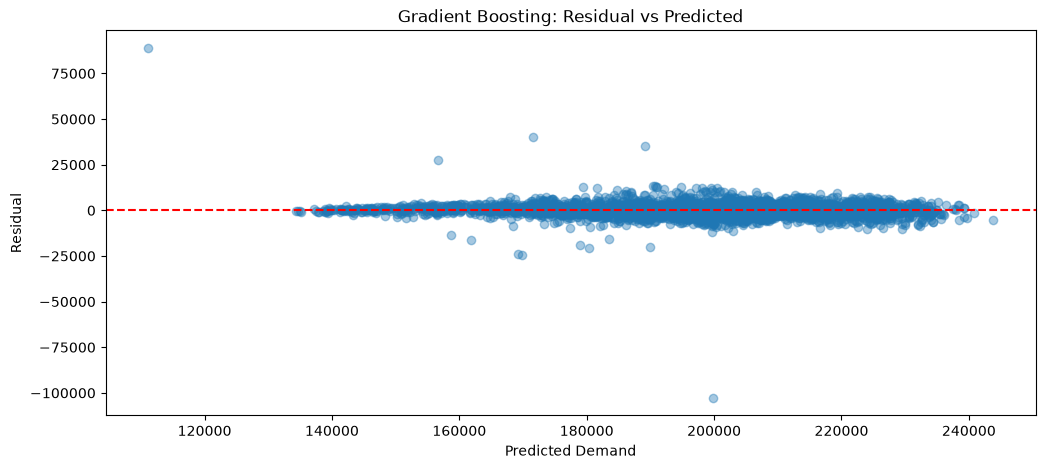

In [20]:
plt.figure(figsize=(12, 5))

plt.scatter(
    error_df['predicted'],
    error_df['residual'],
    alpha=0.4
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Demand')
plt.ylabel('Residual')
plt.title('Gradient Boosting: Residual vs Predicted')

plt.show()

In [21]:
largest_errors = error_df.sort_values(
    by='absolute_error',
    ascending=False
)

largest_errors.head(10)

,datetime,actual,predicted,residual,absolute_error
2248,2025-04-04 16:00:00,97065.28,199864.477591,-102799.197591,102799.197591
2249,2025-04-04 17:00:00,200036.27,111101.305377,88934.964623,88934.964623
800,2025-02-03 08:00:00,211513.48,171567.122880,39946.357120,39946.357120
178,2025-01-08 10:00:00,224407.78,189106.345376,35301.434624,35301.434624
177,2025-01-08 09:00:00,183988.91,156579.526236,27409.383764,27409.383764
175,2025-01-08 07:00:00,145392.78,169877.264249,-24484.484249,24484.484249
174,2025-01-08 06:00:00,145392.78,169158.200346,-23765.420346,23765.420346
799,2025-02-03 07:00:00,159777.55,180435.820841,-20658.270841,20658.270841
222,2025-01-10 06:00:00,169946.50,189941.538658,-19995.038658,19995.038658
798,2025-02-03 06:00:00,159777.55,178969.623291,-19192.073291,19192.073291


In [22]:
error_df = error_df.sort_values('datetime')

timestamp = pd.Timestamp('2025-04-04 16:00:00')

nearby_rows = error_df[
    (error_df['datetime'] >= timestamp - pd.Timedelta(hours=3)) &
    (error_df['datetime'] <= timestamp + pd.Timedelta(hours=3))
]

nearby_rows

,datetime,actual,predicted,residual,absolute_error
2245,2025-04-04 13:00:00,195807.58,197871.215313,-2063.635313,2063.635313
2246,2025-04-04 14:00:00,199623.78,198910.164042,713.615958,713.615958
2247,2025-04-04 15:00:00,203399.28,200986.861943,2412.418057,2412.418057
2248,2025-04-04 16:00:00,97065.28,199864.477591,-102799.197591,102799.197591
2249,2025-04-04 17:00:00,200036.27,111101.305377,88934.964623,88934.964623
2250,2025-04-04 18:00:00,201745.65,196761.503123,4984.146877,4984.146877
2251,2025-04-04 19:00:00,209134.11,208269.791786,864.318214,864.318214


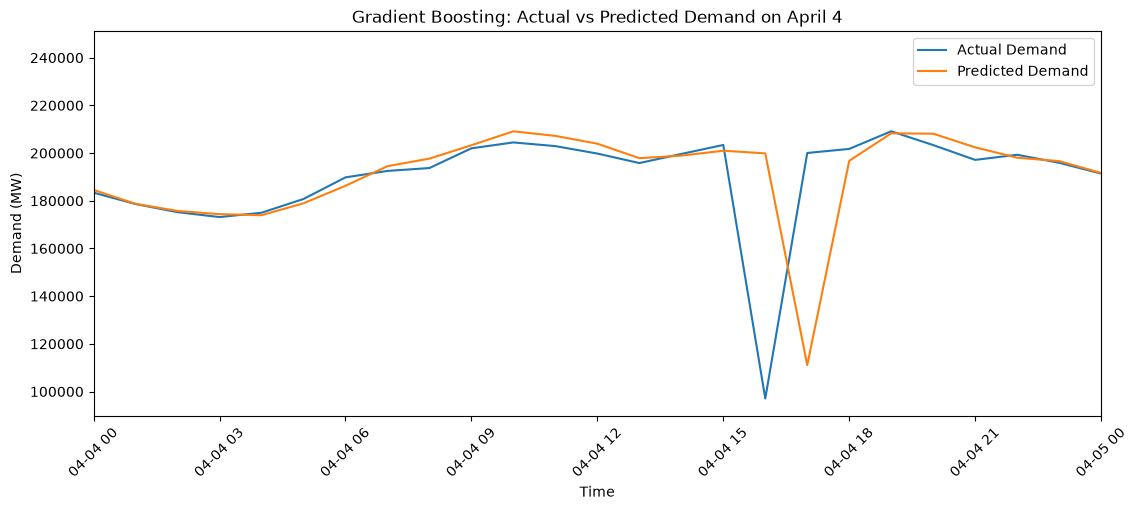

In [23]:
plt.figure(figsize=(13, 5))

plt.plot(
    error_df['datetime'],
    error_df['actual'],
    label='Actual Demand'
)

plt.plot(
    error_df['datetime'],
    error_df['predicted'],
    label='Predicted Demand'
)

plt.xlim(
    pd.Timestamp('2025-04-04 00:00:00'),
    pd.Timestamp('2025-04-05 00:00:00')
)

plt.xlabel('Time')
plt.ylabel('Demand (MW)')
plt.title('Gradient Boosting: Actual vs Predicted Demand on April 4')
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [24]:
same = df['national_demand_mw'].diff() == 0
print(same.sum(), 'hours where demand is exactly equal to the previous hour')
df.loc[same, ['datetime', 'national_demand_mw']].head(30)

25 hours where demand is exactly equal to the previous hour


,datetime,national_demand_mw
47674,2024-06-16 10:00:00,205383.33
47675,2024-06-16 11:00:00,205383.33
48279,2024-07-11 15:00:00,215666.47
52613,2025-01-08 05:00:00,145392.78
52614,2025-01-08 06:00:00,145392.78
52615,2025-01-08 07:00:00,145392.78
52616,2025-01-08 08:00:00,145392.78
52629,2025-01-08 21:00:00,203763.52
52630,2025-01-08 22:00:00,203763.52
52631,2025-01-08 23:00:00,203763.52


In [29]:
from xgboost import XGBRegressor

xgb = XGBRegressor(random_state=42, n_jobs=-1)   
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

xgb_metrics = get_metrics(y_test, xgb_pred, X_train.shape[1])
xgb_metrics

{'MAE': 2517.927534449405,
 'MAPE': 1.2769687096883309,
 'RMSE': np.float64(3980.573316126437),
 'R2': 0.958560091315707,
 'Adj_R2': 0.9584413239633756}

In [30]:
xgb_search = tune(
    XGBRegressor(tree_method='hist', random_state=42, n_jobs=1),
    {
        'n_estimators': [300, 600, 1000],
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [4, 6, 8],
        'subsample': [0.6, 0.7, 0.85],
        'colsample_bytree': [0.7, 0.85, 1.0],
        'min_child_weight': [1, 5, 10],
        'reg_lambda': [1, 5, 10],
    },
    n_iter=20
)

xgb_tuned = xgb_search.best_estimator_
xgb_tuned_pred = xgb_tuned.predict(X_test)
xgb_tuned_metrics = get_metrics(y_test, xgb_tuned_pred, X_train.shape[1])
xgb_tuned_metrics

Fitting 3 folds for each of 20 candidates, totalling 60 fits
best params: {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 1000, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.85}
CV MAPE: 1.23%


{'MAE': 2322.3181015625,
 'MAPE': 1.1769397191630764,
 'RMSE': np.float64(3850.5120483481974),
 'R2': 0.9612238659319473,
 'Adj_R2': 0.9611127329945658}

In [31]:
naive = {
    'Naive: last hour': test['demand_lag1'],
    'Naive: same hour yesterday': test['demand_lag24'],
    'Naive: same hour last week': test['demand_lag168'],
}
naive_results = pd.DataFrame(
    {k: get_metrics(y_test, v, X_train.shape[1]) for k, v in naive.items()}
).T
naive_results

,MAE,MAPE,RMSE,R2,Adj_R2
Naive: last hour,4599.005564,2.355829,6449.065624,0.891227,0.890915
Naive: same hour yesterday,5949.873602,3.065108,9075.428155,0.784592,0.783975
Naive: same hour last week,9012.443986,4.577593,12536.940137,0.588935,0.587757


In [32]:
final = pd.DataFrame({
    'MLR': mlr_metrics,
    'Random Forest': rf_metrics,
    'SVR (tuned)': svr_tuned_metrics,
    'AdaBoost (tuned)': ada_tuned_metrics,
    'GradBoost (tuned)': gb_tuned_metrics,
    'XGBoost (tuned)': xgb_tuned_metrics,
}).T

final = pd.concat([final, naive_results])
final.sort_values('MAPE').round(3)

,MAE,MAPE,RMSE,R2,Adj_R2
GradBoost (tuned),2284.095,1.164,3813.107,0.962,0.962
XGBoost (tuned),2322.318,1.177,3850.512,0.961,0.961
AdaBoost (tuned),2615.770,1.323,4094.521,0.956,0.956
Random Forest,2728.616,1.381,4158.289,0.955,0.955
MLR,3479.252,1.775,5037.884,0.934,0.933
SVR (tuned),4367.398,2.153,6510.731,0.889,0.889
Naive: last hour,4599.006,2.356,6449.066,0.891,0.891
Naive: same hour yesterday,5949.874,3.065,9075.428,0.785,0.784
Naive: same hour last week,9012.444,4.578,12536.940,0.589,0.588


In [33]:
from sklearn.ensemble import RandomForestRegressor

rf_search = tune(
    RandomForestRegressor(random_state=42, n_jobs=1),
    {
        'n_estimators': [200, 400],
        'max_depth': [10, 15, 20, None],
        'min_samples_leaf': [1, 5, 10],
        'max_features': [0.5, 0.8, 1.0],
    },
    n_iter=10
)

rf_tuned_pred = rf_search.best_estimator_.predict(X_test)
rf_tuned_metrics = get_metrics(y_test, rf_tuned_pred, X_train.shape[1])
rf_tuned_metrics

Fitting 3 folds for each of 10 candidates, totalling 30 fits
best params: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': None}
CV MAPE: 1.36%


{'MAE': 2777.1375889532437,
 'MAPE': 1.4070582089135857,
 'RMSE': np.float64(4201.021396141955),
 'R2': 0.9538430267806107,
 'Adj_R2': 0.9537107402559791}